# День 4

# ЗАДАЧА 1: Токенизация текстов

In [3]:
model_name = "distilbert-base-uncased"

In [4]:
from transformers import AutoModel

model = AutoModel.from_pretrained(
    model_name,
    output_attentions=True  # важно!
)
model.eval()

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 6662.17it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [5]:
#грузим токенизатор
from transformers import AutoModel
from transformers import AutoTokenizer
import torch
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [6]:
def tokenize_texts(texts, max_length=128):
    return tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt"
    )

In [7]:
text = ['this is very important!']

In [8]:
result = tokenize_texts(text)

In [9]:
result

{'input_ids': tensor([[ 101, 2023, 2003, 2200, 2590,  999,  102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1]])}

In [10]:
batch = tokenize_texts(["This movie was great!", "Terrible movie, waste of time."])
print(batch["input_ids"].shape)
print(batch["attention_mask"])

torch.Size([2, 9])
tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1]])


# ЗАДАЧА 2: Извлечение CLS-эмбеддингов

In [11]:
model = AutoModel.from_pretrained(model_name)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 13683.62it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [12]:
model.eval()

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [13]:
import numpy as np
import torch

def get_cls_embeddings(texts, batch_size=32):
    all_embeddings = []

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]       # очередные batch_size текстов
        batch = tokenize_texts(batch_texts)                  # функция из задачи 1

        with torch.no_grad():                                # градиенты не нужны, только предсказание
            outputs = model(**batch)

        cls = outputs.last_hidden_state[:, 0, :]             # вектор [CLS] для каждого текста
        all_embeddings.append(cls.cpu().numpy())

    return np.vstack(all_embeddings)                         # склеиваем батчи в одну матрицу

In [14]:
texts = [
    "This movie was great!",
    "Terrible movie, waste of time.",
    "I love you!"
]

emb = get_cls_embeddings(texts, batch_size=2)
print(emb.shape)

(3, 768)


# ЗАДАЧА 3: Logistic Regression на эмбеддингах

In [15]:
from datasets import load_dataset
import pandas as pd

imdb = load_dataset("stanfordnlp/imdb")
df = imdb["train"].shuffle(seed=42).select(range(2000)).to_pandas()[["text", "label"]]

import os
os.makedirs("data", exist_ok=True)
df.to_csv("data/imdb_2000.csv", index=False)

print(df.shape)
print(df["label"].value_counts())

(2000, 2)
label
1    1000
0    1000
Name: count, dtype: int64


In [16]:
texts = df["text"].tolist()
y = df["label"].values

X = get_cls_embeddings(texts)
print(X.shape)   # (2000, 768)

(2000, 768)


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)   # (1600, 768) (400, 768)

(1600, 768) (400, 768)


In [18]:
   clf = LogisticRegression(max_iter=1000, n_jobs=-1)
   clf.fit(X_train, y_train)
   y_pred = clf.predict(X_test)

/Users/mak/Desktop/WORKPLACE/ML_валютная удаленка/Проекты/transformers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [19]:
print(classification_report(y_test, y_pred))

f1 = f1_score(y_test, y_pred, average="macro")
print(f"Macro F1: {f1:.4f}")

with open("baseline_results.txt", "w") as f:
    f.write(f"Baseline: DistilBERT CLS embeddings + LogisticRegression\n")
    f.write(f"Macro F1: {f1:.4f}\n")

              precision    recall  f1-score   support

           0       0.81      0.83      0.82       200
           1       0.83      0.81      0.82       200

    accuracy                           0.82       400
   macro avg       0.82      0.82      0.82       400
weighted avg       0.82      0.82      0.82       400

Macro F1: 0.8200


# День 5

# ЗАДАЧА 1: Подготовка Dataset класса

In [20]:
from torch.utils.data import Dataset

class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            padding='max_length',
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

# ЗАДАЧА 2: Загрузка и подготовка данных

In [21]:
import pandas as pd

df = pd.read_csv('imdb_2000.csv')
texts = df['text'].tolist()
labels = df['label'].tolist()

In [22]:
from sklearn.model_selection import train_test_split

train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)

In [23]:
from transformers import AutoTokenizer

In [24]:
#грузим токенизатор
from transformers import AutoModel
from transformers import AutoTokenizer
import torch
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [25]:
train_dataset = SentimentDataset(train_texts, train_labels, tokenizer)
val_dataset = SentimentDataset(val_texts, val_labels, tokenizer)

# ЗАДАЧА 3: Загрузка модели для классификации

In [26]:
from transformers import AutoModelForSequenceClassification

# Определите количество классов
num_labels = len(set(labels))  # 2 для бинарной, 3 для positive/negative/neutral

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_labels
)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 11081.68it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [27]:
from transformers import AutoModelForSequenceClassification

# Определите количество классов
num_labels = len(set(labels))  # 2 для бинарной, 3 для positive/negative/neutral

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_labels
)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 11686.55it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [28]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)

# ЗАДАЧА 4: Настройка обучения

In [29]:
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score

optimizer = AdamW(model.parameters(), lr=2e-5)

In [30]:
optimizer = AdamW(model.parameters(), lr=2e-5)

In [31]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

# ЗАДАЧА 5: Функция для обучения одной эпохи

In [32]:
def train_epoch(model, dataloader, optimizer, device):
    model.train()
    total_loss = 0

    for batch in dataloader:
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)

# ЗАДАЧА 6: Функция для оценки

In [33]:
def evaluate(model, dataloader, device):
    model.eval()
    predictions = []
    true_labels = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            preds = torch.argmax(outputs.logits, dim=1)
            predictions.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average='macro')

    return accuracy, f1

# ЗАДАЧА 7: Обучение модели

In [34]:
num_epochs = 3

for epoch in range(num_epochs):
    train_loss = train_epoch(model, train_loader, optimizer, device)
    val_acc, val_f1 = evaluate(model, val_loader, device)

    print(f'Epoch {epoch+1}/{num_epochs}')
    print(f'Train Loss: {train_loss:.4f}')
    print(f'Val Accuracy: {val_acc:.4f}')
    print(f'Val F1: {val_f1:.4f}')
    print('-' * 50)

Epoch 1/3
Train Loss: 0.5397
Val Accuracy: 0.8350
Val F1: 0.8339
--------------------------------------------------
Epoch 2/3
Train Loss: 0.2902
Val Accuracy: 0.8175
Val F1: 0.8159
--------------------------------------------------
Epoch 3/3
Train Loss: 0.1670
Val Accuracy: 0.8500
Val F1: 0.8500
--------------------------------------------------


# ЗАДАЧА 8: Сохранение модели

In [35]:
model.save_pretrained('./fine_tuned_model')
tokenizer.save_pretrained('./fine_tuned_model')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.95it/s]


('./fine_tuned_model/tokenizer_config.json',
 './fine_tuned_model/tokenizer.json')

In [36]:
with open('fine_tuned_results.txt', 'w') as f:
    f.write(f'Final Validation F1: {val_f1:.4f}\n')
    f.write(f'Final Validation Accuracy: {val_acc:.4f}\n')

# День 6

# ЗАДАЧА 1: Загрузка моделей

In [37]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer
import torch

model_ft = AutoModelForSequenceClassification.from_pretrained('./fine_tuned_model')
tokenizer = AutoTokenizer.from_pretrained('./fine_tuned_model')
model_ft.eval()

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 7176.24it/s]


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [40]:
import joblib
import numpy as np
import torch
from transformers import AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# 1. Исходный DistilBERT без дообучения — "векторайзер" бейзлайна
base_encoder = AutoModel.from_pretrained(model_name)
base_encoder.eval()

def get_cls_embeddings_base(texts, batch_size=32):
    all_embeddings = []
    for start in range(0, len(texts), batch_size):
        batch = tokenize_texts(texts[start:start + batch_size])
        with torch.no_grad():
            outputs = base_encoder(**batch)
        all_embeddings.append(outputs.last_hidden_state[:, 0, :].cpu().numpy())
    return np.vstack(all_embeddings)

# 2. Пересобираем бейзлайн на тех же данных и том же сплите, что в Дне 4
X = get_cls_embeddings_base(texts)
y = np.array(labels)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train, y_train)

# 3. Сохраняем, чтобы дальше грузить из файла, как просит задание
joblib.dump(baseline_model, "baseline_model.pkl")
print("Baseline accuracy:", baseline_model.score(X_test, y_test))

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 13523.03it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Baseline accuracy: 0.82


In [41]:
baseline_model = joblib.load("baseline_model.pkl")

# Бейзлайн в Дне 4 — CLS-эмбеддинги DistilBERT + LogisticRegression,
# поэтому вместо TF-IDF vectorizer.pkl используем обёртку над DistilBERT
class CLSVectorizer:
    def transform(self, texts):
        return get_cls_embeddings_base(list(texts))

baseline_vectorizer = CLSVectorizer()

# ЗАДАЧА 2: Функция предсказания для fine-tuned

In [43]:
def predict_fine_tuned(texts, model, tokenizer):
    if isinstance(texts, str):
        texts = [texts]

    predictions = []

    for text in texts:
        inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128)

        with torch.no_grad():
            outputs = model(**inputs)

        probs = torch.nn.functional.softmax(outputs.logits, dim=1)
        pred = torch.argmax(probs, dim=1).item()

        predictions.append({
            'text': text,
            'prediction': pred,
            'probabilities': probs[0].cpu().numpy()
        })

    return predictions

# ЗАДАЧА 3: Функция предсказания для baseline

In [44]:
def predict_baseline(texts, model, vectorizer, clean_func=None):
    if isinstance(texts, str):
        texts = [texts]

    if clean_func:
        texts = [clean_func(t) for t in texts]

    X = vectorizer.transform(texts)
    predictions = model.predict(X)
    probs = model.predict_proba(X) if hasattr(model, 'predict_proba') else None

    results = []
    for i, text in enumerate(texts):
        results.append({
            'text': text,
            'prediction': int(predictions[i]),
            'probabilities': probs[i] if probs is not None else None
        })

    return results

# ЗАДАЧА 4: Сравнение на примерах

In [45]:
test_texts = [
    "This movie was absolutely fantastic!",
    "Terrible, waste of my time.",
    "It was okay, nothing special.",
    "Best film I've seen this year!",
    "Boring and too long."
]

In [46]:
# Fine-tuned predictions
preds_ft = predict_fine_tuned(test_texts, model_ft, tokenizer)

# Baseline predictions (если есть)
if baseline_model:
    preds_baseline = predict_baseline(test_texts, baseline_model, baseline_vectorizer)

In [47]:
for i, text in enumerate(test_texts):
    print(f'\nТекст: {text}')
    print(f'Fine-tuned: {preds_ft[i]["prediction"]} (probs: {preds_ft[i]["probabilities"]})')
    if baseline_model:
        print(f'Baseline: {preds_baseline[i]["prediction"]}')
        print(f'Совпадают: {preds_ft[i]["prediction"] == preds_baseline[i]["prediction"]}')


Текст: This movie was absolutely fantastic!
Fine-tuned: 1 (probs: [0.01353552 0.9864645 ])
Baseline: 1
Совпадают: True

Текст: Terrible, waste of my time.
Fine-tuned: 0 (probs: [0.9873467  0.01265329])
Baseline: 0
Совпадают: True

Текст: It was okay, nothing special.
Fine-tuned: 0 (probs: [0.9078406  0.09215939])
Baseline: 1
Совпадают: False

Текст: Best film I've seen this year!
Fine-tuned: 1 (probs: [0.03199722 0.96800286])
Baseline: 1
Совпадают: True

Текст: Boring and too long.
Fine-tuned: 0 (probs: [0.9627     0.03729998])
Baseline: 0
Совпадают: True


# ЗАДАЧА 5: Confusion Matrix для обеих моделей

In [50]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('imdb_2000.csv')
_, test_df, _, _ = train_test_split(df, df['label'], test_size=0.2, random_state=42, stratify=df['label'])

test_texts = test_df['text'].tolist()
test_labels = test_df['label'].tolist()

In [51]:
preds_ft_all = predict_fine_tuned(test_texts, model_ft, tokenizer)
y_pred_ft = [p['prediction'] for p in preds_ft_all]

In [52]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_ft = confusion_matrix(test_labels, y_pred_ft)

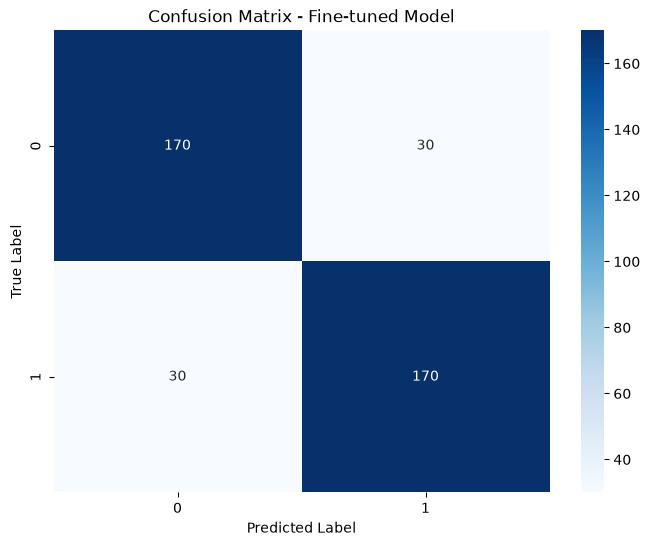

In [53]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm_ft, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Fine-tuned Model')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.savefig('confusion_matrix_finetuned.png')

# ЗАДАЧА 6: Сравнение метрик

In [54]:
from sklearn.metrics import classification_report, f1_score, accuracy_score

# Fine-tuned
print("=== Fine-tuned Model ===")
print(classification_report(test_labels, y_pred_ft))
f1_ft = f1_score(test_labels, y_pred_ft, average='macro')
acc_ft = accuracy_score(test_labels, y_pred_ft)

# Baseline (если есть)
if baseline_model:
    preds_baseline_all = predict_baseline(test_texts, baseline_model, baseline_vectorizer)
    y_pred_base = [p['prediction'] for p in preds_baseline_all]

    print("\n=== Baseline Model ===")
    print(classification_report(test_labels, y_pred_base))
    f1_base = f1_score(test_labels, y_pred_base, average='macro')
    acc_base = accuracy_score(test_labels, y_pred_base)

    print(f'\n=== Сравнение ===')
    print(f'Fine-tuned F1: {f1_ft:.4f}, Accuracy: {acc_ft:.4f}')
    print(f'Baseline F1: {f1_base:.4f}, Accuracy: {acc_base:.4f}')
    print(f'Улучшение F1: {(f1_ft - f1_base) / f1_base * 100:.2f}%')

=== Fine-tuned Model ===
              precision    recall  f1-score   support

           0       0.85      0.85      0.85       200
           1       0.85      0.85      0.85       200

    accuracy                           0.85       400
   macro avg       0.85      0.85      0.85       400
weighted avg       0.85      0.85      0.85       400


=== Baseline Model ===
              precision    recall  f1-score   support

           0       0.81      0.83      0.82       200
           1       0.83      0.81      0.82       200

    accuracy                           0.82       400
   macro avg       0.82      0.82      0.82       400
weighted avg       0.82      0.82      0.82       400


=== Сравнение ===
Fine-tuned F1: 0.8500, Accuracy: 0.8500
Baseline F1: 0.8200, Accuracy: 0.8200
Улучшение F1: 3.66%


# ЗАДАЧА 7: Сохранение результатов сравнения

In [55]:
with open('comparison_results.txt', 'w') as f:
    f.write('=== Сравнение моделей ===\n\n')
    f.write(f'Fine-tuned Model:\n')
    f.write(f'  F1 (macro): {f1_ft:.4f}\n')
    f.write(f'  Accuracy: {acc_ft:.4f}\n')

    if baseline_model:
        f.write(f'\nBaseline Model:\n')
        f.write(f'  F1 (macro): {f1_base:.4f}\n')
        f.write(f'  Accuracy: {acc_base:.4f}\n')
        f.write(f'\nУлучшение: {(f1_ft - f1_base) / f1_base * 100:.2f}%\n')

# День 7

# ЗАДАЧА 1: Анализ False Positive и False Negative

In [56]:
import pandas as pd

# Загрузите данные и предсказания из Дня 6
df_test = pd.DataFrame({
    'text': test_texts,
    'true_label': test_labels,
    'pred_label': y_pred_ft
})

# Найдите ошибки
errors = df_test[df_test['true_label'] != df_test['pred_label']]

# False Positives (предсказала positive, а было negative/neutral)
fp = errors[(errors['pred_label'] == 1) & (errors['true_label'] == 0)]

# False Negatives (предсказала negative, а было positive)
fn = errors[(errors['pred_label'] == 0) & (errors['true_label'] == 1)]

print(f'Всего ошибок: {len(errors)}')
print(f'False Positives: {len(fp)}')
print(f'False Negatives: {len(fn)}')

Всего ошибок: 60
False Positives: 30
False Negatives: 30


# ЗАДАЧА 2: Анализ паттернов ошибок

In [57]:
print("\n=== FALSE POSITIVES (сказали good, а было bad) ===")
for idx, row in fp.head(5).iterrows():
    print(f'\nТекст: {row["text"][:100]}...')
    print(f'Истинный класс: {row["true_label"]}, Предсказан: {row["pred_label"]}')

print("\n=== FALSE NEGATIVES (сказали bad, а было good) ===")
for idx, row in fn.head(5).iterrows():
    print(f'\nТекст: {row["text"][:100]}...')
    print(f'Истинный класс: {row["true_label"]}, Предсказан: {row["pred_label"]}')


=== FALSE POSITIVES (сказали good, а было bad) ===

Текст: I had a lot of expectations from this movie and more so since it was a Yashraj Film.<br /><br />Jimm...
Истинный класс: 0, Предсказан: 1

Текст: I first saw this movie on MST3K. And although I laughed my posterior off at the jokes, I don't parti...
Истинный класс: 0, Предсказан: 1

Текст: This mini-series is actually more entertaining than some others with much bigger budgets and grander...
Истинный класс: 0, Предсказан: 1

Текст: I wanted to read the other comments before leaving my review and the majority definately rules: This...
Истинный класс: 0, Предсказан: 1

Текст: Sitting down to watch the 14th season of the Bachelor ("On the Wings of Love"), I knew I would be in...
Истинный класс: 0, Предсказан: 1

=== FALSE NEGATIVES (сказали bad, а было good) ===

Текст: This movie is ridiculous! That's exactly what I like about this piece of "Guilty Pleasure". It is ea...
Истинный класс: 1, Предсказан: 0

Текст: I rented this movi

In [58]:
errors['text_length'] = errors['text'].str.len()
print(f'\nСредняя длина ошибочных текстов: {errors["text_length"].mean():.0f}')
print(f'Средняя длина всех текстов: {df_test["text"].str.len().mean():.0f}')


Средняя длина ошибочных текстов: 1760
Средняя длина всех текстов: 1252


In [59]:
with open('error_analysis.txt', 'w') as f:
    f.write('=== АНАЛИЗ ОШИБОК ===\n\n')
    f.write(f'Всего ошибок: {len(errors)}\n')
    f.write(f'False Positives: {len(fp)}\n')
    f.write(f'False Negatives: {len(fn)}\n\n')

    f.write('=== ПРИМЕРЫ FALSE POSITIVES ===\n')
    for idx, row in fp.head(5).iterrows():
        f.write(f'\nТекст: {row["text"]}\n')
        f.write(f'Истинный: {row["true_label"]}, Предсказан: {row["pred_label"]}\n')

    f.write('\n\n=== ПРИМЕРЫ FALSE NEGATIVES ===\n')
    for idx, row in fn.head(5).iterrows():
        f.write(f'\nТекст: {row["text"]}\n')
        f.write(f'Истинный: {row["true_label"]}, Предсказан: {row["pred_label"]}\n')

    # Добавьте ваши наблюдения
    f.write('\n\n=== НАБЛЮДЕНИЯ ===\n')
    f.write('Добавьте сюда ваши выводы о паттернах ошибок...\n')

# ЗАДАЧА 3: Создание демо-приложения (Gradio)

In [60]:
pip install gradio

  Using cached pillow-12.3.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached typing_inspection-0.4.4-py3-none-any.whl.metadata (2.6 kB)
  Using cached annotated_types-0.8.0-py3-none-any.whl.metadata (15 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 4.9 MB/s  0:00:06m0:00:0100:01
Using cached pillow-12.3.0-cp313-cp313-macosx_11_0_arm64.whl (4.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 5.9 MB/s  0:00:00 eta 0:00:01
Using cached annotated_types-0.8.0-py3-none-any.whl (13 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 861.7/861.7 kB 6.1 MB/s  0:00:00
Using cached typing_inspection-0.4.4-py3-none-any.whl (14 kB)
Using cached uvicorn-0.54.0-py3-none-any.whl (87 kB)
  Attempting uninstall: pillowm━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  5/22 [tomlkit]
    Found existing installation: pillow 13.0.0━━━━━━━━━━━━━━━━━━━━  9/22 [pillow]
    Uninstalling pillow-13.0.0:━━━━━━━━━━━━━━━━━━━━━━━

In [61]:
import gradio as gr

def predict_sentiment(text):
    """
    Функция для Gradio интерфейса
    """
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128)

    with torch.no_grad():
        outputs = model_ft(**inputs)

    probs = torch.nn.functional.softmax(outputs.logits, dim=1)
    pred = torch.argmax(probs, dim=1).item()

    label_map = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}

    # Форматируем вывод вероятностей
    result = f"Prediction: {label_map.get(pred, pred)}\n\n"
    result += "Probabilities:\n"

    for i, prob in enumerate(probs[0]):
        result += f"{label_map.get(i, i)}: {prob*100:.2f}%\n"

    return result

# Создаём интерфейс
demo = gr.Interface(
    fn=predict_sentiment,
    inputs=gr.Textbox(lines=3, placeholder="Введите текст для анализа..."),
    outputs=gr.Textbox(label="Результат"),
    title="Sentiment Analysis с BERT",
    description="Введите текст и модель определит его тональность"
)

if __name__ == "__main__":
    demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [62]:
python app.py

SyntaxError: invalid syntax (945115591.py, line 1)